# Spot transit: $T_s$ and Dumusque bisector $\times (a + b\mu)$

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import copy
import numpy as np
import matplotlib.pyplot as plt

from sunsim import *
from sunsim import local_path

## Parameters

In [2]:
rotation_period = 24.47            # [days]
stellar_radius = 1
inclination = 0
differential_rotation = SOLAR_DIFFERENTIAL_ROTATION
T_quiet = 5770                     # [K]

spot_dTs = [300, 600, 1100]        # [K] T_quiet - T_spot
mu_scalings = {'Dumusque (1, 0)': (1, 0), 'Dumusque (0, 1)': (0, 1), 'Dumusque (0, 0.5)': (0, 0.5)}
spot = [active_region('sp', 10, 90, 180)]       # radius 10 deg, equator

time = np.linspace(0, rotation_period, 100)
N_rings_phot = 30
N_rings_ccf = 30

## Spectra

In [3]:
flux_quiet = np.load(str(local_path('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_quiet_low = np.load(str(local_path('muram_lowres_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy'), allow_pickle=True).item()
flux_fc = np.load(str(local_path('muram_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_fc_low = np.load(str(local_path('muram_lowres_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy'), allow_pickle=True).item()
flux_sp_raw = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_sp_low_raw = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_PHOENIX_low_res_specint_grid.npy'), allow_pickle=True).item()

for mu in flux_sp_low_raw:
    conv = (1e-8 * flux_sp_low_raw[mu]['wav']**2 * 2.99792458e10) / 1e12
    flux_sp_low_raw[mu]['intensity'] /= conv
    flux_quiet_low[mu]['intensity'] /= conv
    flux_fc_low[mu]['intensity'] /= conv


def cooler(flux, dT):
    out = copy.deepcopy(flux)
    for mu, d in out.items():
        d['intensity'] *= black_body(d['wav'], T_quiet - dT) / black_body(d['wav'], T_quiet)
    return out

## Photometry

In [4]:
def photometry_grid(flux_low, typ):
    g = flux_grid(N_rings_phot, flux_low, typ, None, 3800, 8000, rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
    g.built_grid()
    return g

phot_quiet = photometry_grid(flux_quiet_low, 'quiet')
phot_fc = photometry_grid(flux_fc_low, 'fc')

photometry = {}
for dT in spot_dTs:
    phot_sp = photometry_grid(cooler(flux_sp_low_raw, dT), 'sp')
    ss = StarSim(time, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=differential_rotation, active_regions_map=spot, mode=['photometry'],
                 stellar_radius=stellar_radius,
                 flux_grid_qp=phot_quiet.grid, flux_grid_sp=phot_sp.grid, flux_grid_fc=phot_fc.grid)
    ss.generate_timeseries(verbose=False)
    photometry[dT] = 100 * (ss.flux_var / phot_quiet.total_brightness - 1)

## CCF

In [5]:
wvm, fm = mask_weights(str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'))
rv_grid = np.arange(-18000, 18025, 25)             # [m/s]


band_ccf = (3800, 6800)             # [A] mask lines


def ring_brightness(flux_low, typ):
    g = flux_grid(N_rings_ccf, flux_low, typ, None, *band_ccf, rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
    g.built_grid()
    return g.amu, g.grid / (g.parea / (4 * np.pi))

amu_ring, b_quiet = ring_brightness(flux_quiet_low, 'quiet')
b_ref = b_quiet[0]


def make_ccf_grid(flux, brightness, convective_blueshift):
    g = CCF_grid(N_rings_ccf, flux, rv_grid, wvm, fm, convective_blueshift=convective_blueshift,
                 phoenix_resolution=True, mu_ratio=brightness / b_ref, normalization=False)
    assert np.allclose(g.amu, amu_ring)
    g.compute_ccf()
    return g

def ring_bisectors(g):
    out = []
    for rv_i, c in zip(g.rvs_ring, g.ccf_shape):
        _, _, xbis, ybis = nbspectra.speed_bisector_nb(rv_i, c / c.max(), True)
        out.append((xbis, ybis))
    return np.array(out)               # (N_rings, [rv [m/s], height], 50)

def ring_rv_fit(g):
    out = []
    for rv_i, c in zip(g.rvs_ring, g.ccf_shape):
        c = c - c.min() + 1e-6
        cl, cr, _, _ = nbspectra.speed_bisector_nb(rv_i, c / c.max(), True)
        x, y = rv_i[int(cl):int(cr)], c[int(cl):int(cr)]
        k = y.argmax()
        p, ok = nbspectra.fit_gaussian_nb(x, y, np.array([y[k], x[k], 3000., 1e-6]), 500)
        out.append(p[1] if ok else np.nan)
    return np.array(out)               # (N_rings,) centre of the gaussian fit [m/s]

bisectors = {}
ring_rvs = {}
ccf_quiet = make_ccf_grid(flux_quiet, b_quiet, 0)
ccf_quiet.rv_treatment(bisector=None)
ccf_fac = make_ccf_grid(flux_fc, ring_brightness(flux_fc_low, 'fc')[1], 0)
ccf_fac.rv_treatment(bisector=None)
bisectors['quiet'] = ring_bisectors(ccf_quiet)
bisectors['facula'] = ring_bisectors(ccf_fac)
ring_rvs['quiet'] = ring_rv_fit(ccf_quiet)
ring_rvs['facula'] = ring_rv_fit(ccf_fac)

ccf = {}
for dT in spot_dTs:
    ccf_spot = make_ccf_grid(cooler(flux_sp_raw, dT), ring_brightness(cooler(flux_sp_low_raw, dT), 'sp')[1], 1)
    for name, ab in mu_scalings.items():
        ccf_spot.rv_treatment(bisector=dumusque_bisector(normalization=False, mu_scaling=ab))
        bisectors[dT, name] = ring_bisectors(ccf_spot)
        ring_rvs[dT, name] = ring_rv_fit(ccf_spot)
        ss = StarSim(time, N_rings_ccf, inclination=inclination, rotation_period=rotation_period,
                     differential_rotation=differential_rotation, active_regions_map=spot, mode=['ccf'],
                     stellar_radius=stellar_radius, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
        ss.generate_timeseries(verbose=False)
        assert ss.ff_sp[0] == 0
        ccf[dT, name] = {'ff_sp': ss.ff_sp.copy(),
                         'rv': ss.rv_var - ss.rv_var[0],
                         'fwhm': ss.fwhm_var - ss.fwhm_var[0],
                         'bis': ss.bis_var - ss.bis_var[0]}

## Photometry and RV

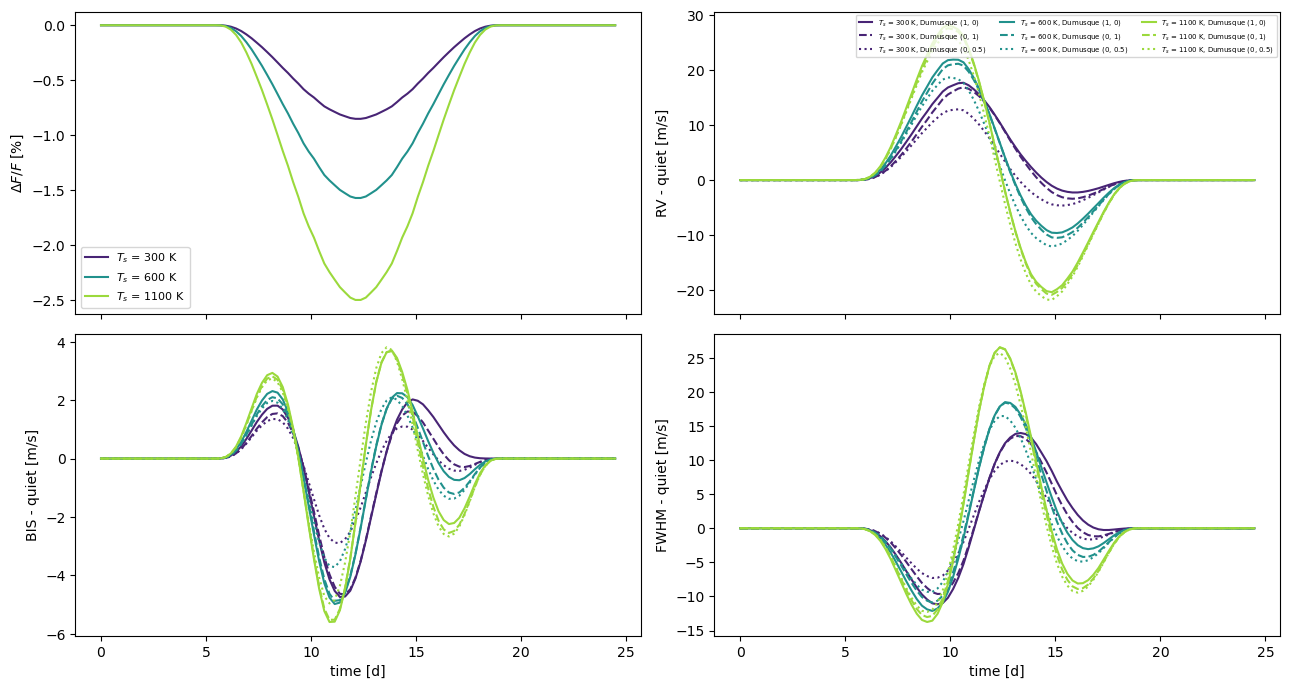

In [6]:
colors = dict(zip(spot_dTs, plt.cm.viridis([0.1, 0.5, 0.85])))
styles = dict(zip(mu_scalings, ['-', '--', ':']))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
ax = axes[0, 0]
for dT in spot_dTs:
    ax.plot(time, photometry[dT], color=colors[dT], label='$T_s$ = %d K' % dT)
ax.set_ylabel('$\\Delta F / F$ [%]')
ax.legend(fontsize=8)

for ax, key, label in ((axes[0, 1], 'rv', 'RV'), (axes[1, 0], 'bis', 'BIS'), (axes[1, 1], 'fwhm', 'FWHM')):
    for dT in spot_dTs:
        for name in mu_scalings:
            ax.plot(time, ccf[dT, name][key], styles[name], color=colors[dT],
                    label='$T_s$ = %d K, %s' % (dT, name))
    ax.set_ylabel('%s - quiet [m/s]' % label)
axes[0, 1].legend(ncol=3,fontsize=5)
for ax in axes[1]:
    ax.set_xlabel('time [d]')
plt.tight_layout()
plt.show()

## Bisector vs $\mu$

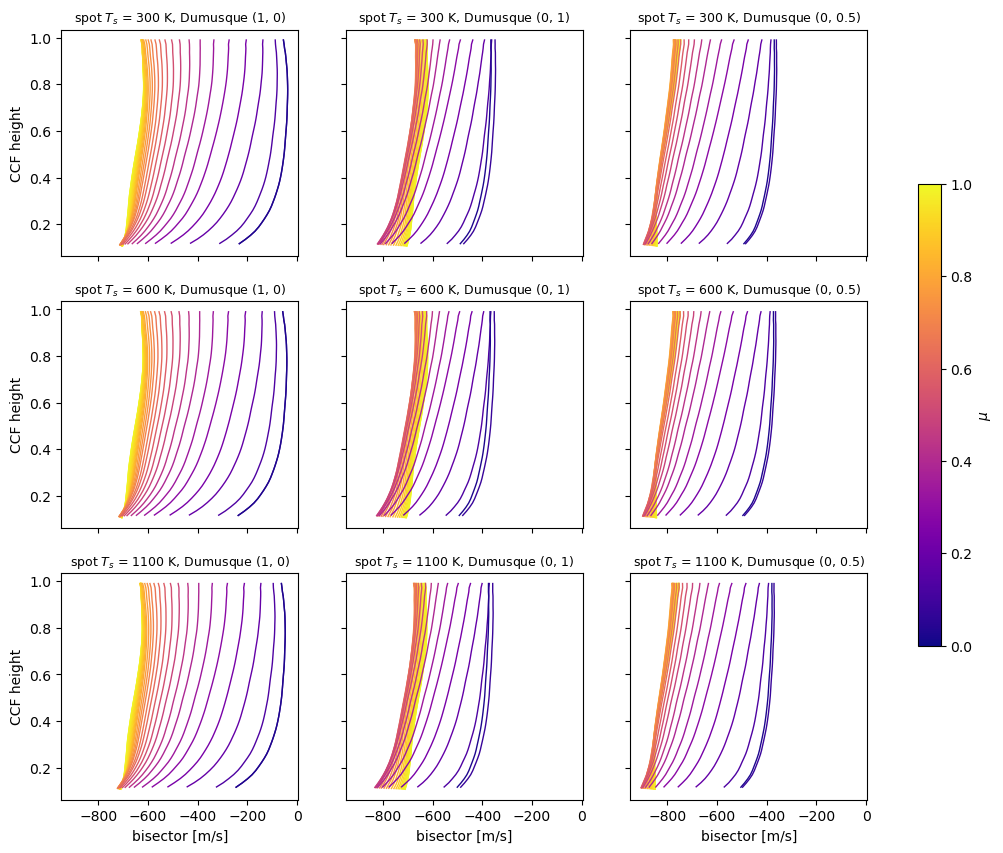

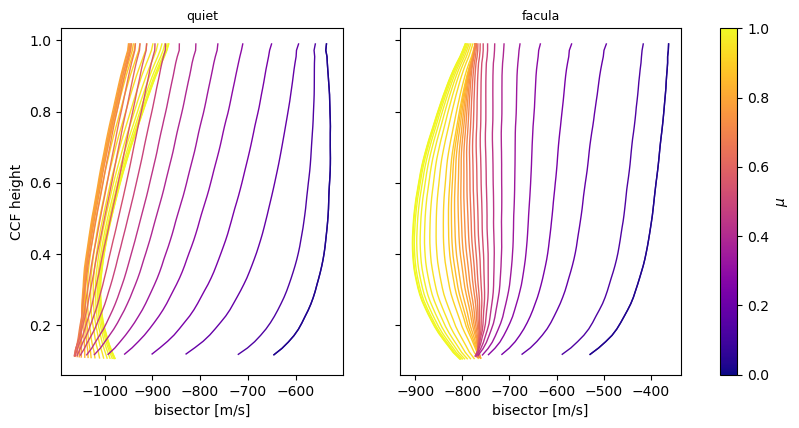

In [7]:
mu_norm = plt.Normalize(0, 1)
mu_cmap = plt.cm.plasma


def plot_bisectors(ax, bis, title):
    for mu, (xbis, ybis) in zip(amu_ring, bis):
        ax.plot(xbis, ybis, color=mu_cmap(mu_norm(mu)), lw=1)
    ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(len(spot_dTs), len(mu_scalings), figsize=(13, 10), sharex=True, sharey=True)
for i, dT in enumerate(spot_dTs):
    for j, name in enumerate(mu_scalings):
        plot_bisectors(axes[i, j], bisectors[dT, name], 'spot $T_s$ = %d K, %s' % (dT, name))
for ax in axes[-1]:
    ax.set_xlabel('bisector [m/s]')
for ax in axes[:, 0]:
    ax.set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=axes, label='$\\mu$', shrink=0.6)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, key in zip(axes, ('quiet', 'facula')):
    plot_bisectors(ax, bisectors[key], key)
    ax.set_xlabel('bisector [m/s]')
axes[0].set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=axes, label='$\\mu$')
plt.show()

## Bisector relative to quiet

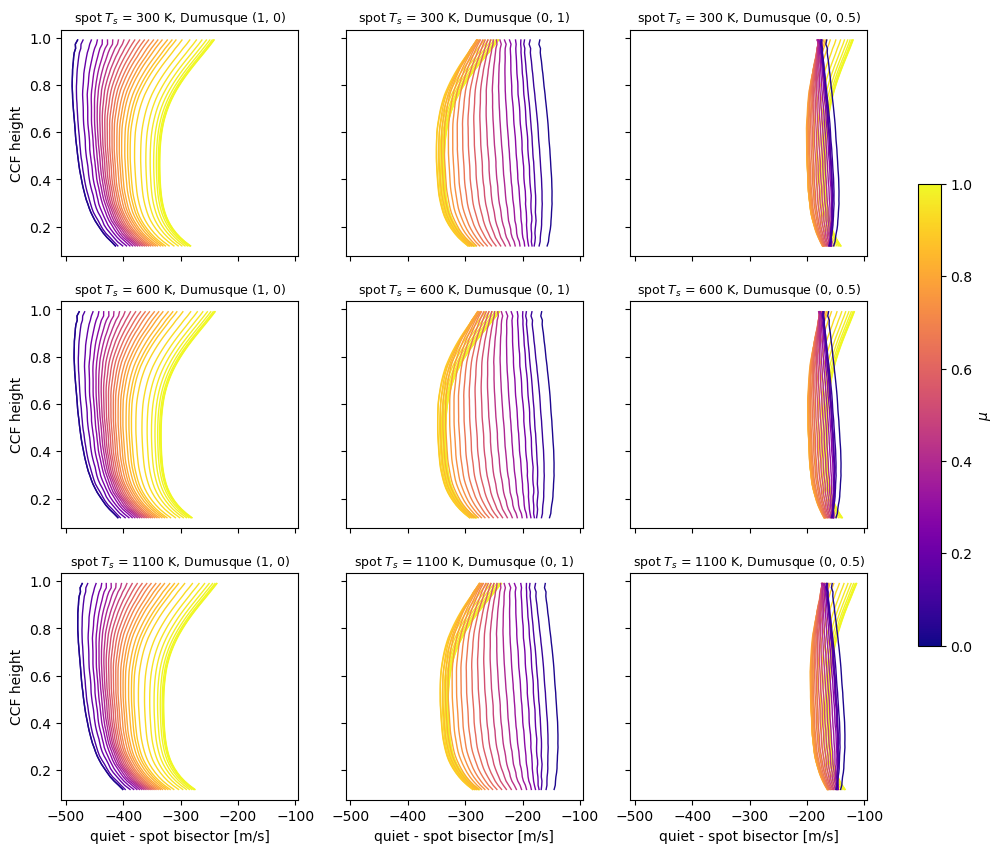

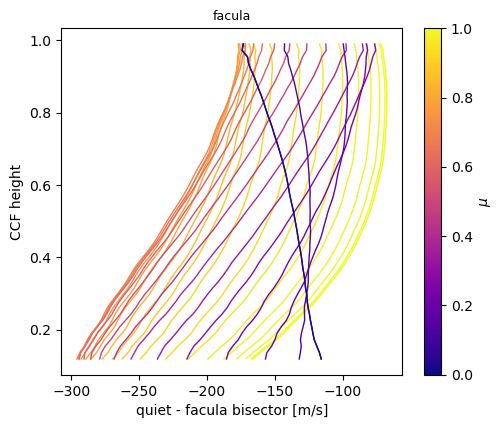

In [8]:
bis_heights = np.linspace(max(b[:, 1, 0].max() for b in bisectors.values()), 0.99, 50)


def relative_to_quiet(bis):
    out = np.empty((len(bis), 2, len(bis_heights)))
    for i, ((xq, yq), (x, y)) in enumerate(zip(bisectors['quiet'], bis)):
        out[i] = np.interp(bis_heights, yq, xq) - np.interp(bis_heights, y, x), bis_heights
    return out


fig, axes = plt.subplots(len(spot_dTs), len(mu_scalings), figsize=(13, 10), sharex=True, sharey=True)
for i, dT in enumerate(spot_dTs):
    for j, name in enumerate(mu_scalings):
        plot_bisectors(axes[i, j], relative_to_quiet(bisectors[dT, name]), 'spot $T_s$ = %d K, %s' % (dT, name))
for ax in axes[-1]:
    ax.set_xlabel('quiet - spot bisector [m/s]')
for ax in axes[:, 0]:
    ax.set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=axes, label='$\\mu$', shrink=0.6)
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_bisectors(ax, relative_to_quiet(bisectors['facula']), 'facula')
ax.set_xlabel('quiet - facula bisector [m/s]')
ax.set_ylabel('CCF height')
fig.colorbar(plt.cm.ScalarMappable(norm=mu_norm, cmap=mu_cmap), ax=ax, label='$\\mu$')
plt.show()

## Median bisector shift vs $\mu$

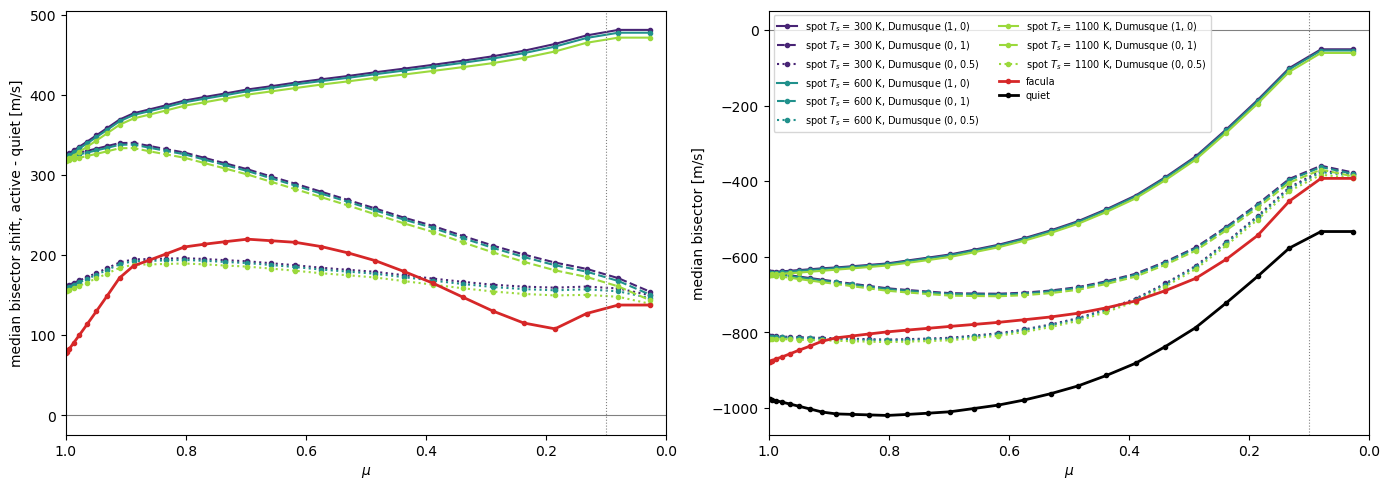

In [9]:
def median_bisector(bis):
    return np.array([np.median(np.interp(bis_heights, y, x)) for x, y in bis])     # median over the heights [m/s]


def median_shift(bis):
    return -np.median(relative_to_quiet(bis)[:, 0], axis=1)      # active - quiet, median over the heights [m/s]


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, f in zip(axes, (median_shift, median_bisector)):
    for dT in spot_dTs:
        for name in mu_scalings:
            ax.plot(amu_ring, f(bisectors[dT, name]), styles[name], marker='.', color=colors[dT],
                    label='spot $T_s$ = %d K, %s' % (dT, name))
    ax.plot(amu_ring, f(bisectors['facula']), 'C3', marker='.', lw=2, label='facula')
    ax.axvline(ccf_fac.limb_lim, color='gray', lw=0.8, ls=':')
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xlabel('$\\mu$')
axes[1].plot(amu_ring, median_bisector(bisectors['quiet']), 'k', marker='.', lw=2, label='quiet')
axes[0].set_ylabel('median bisector shift, active - quiet [m/s]')
axes[1].set_ylabel('median bisector [m/s]')
axes[1].legend(fontsize=7, ncol=2)
axes[0].set_xlim(1,0)
axes[1].set_xlim(1,0)
plt.tight_layout()
plt.show()

## Fitted RV vs $\mu$

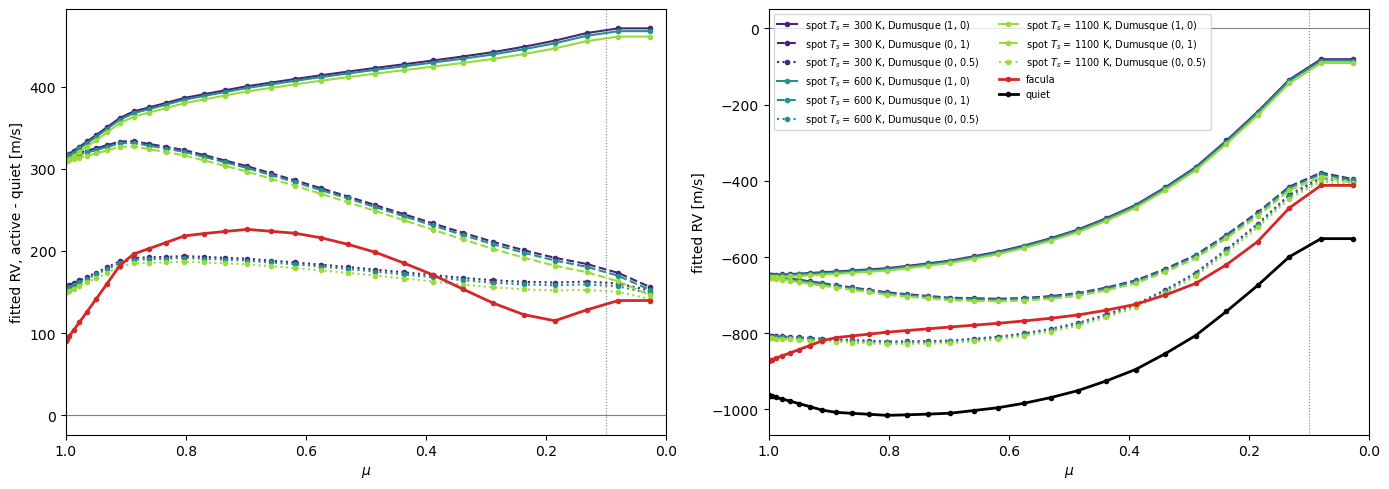

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, ref in zip(axes, (ring_rvs['quiet'], 0)):
    for dT in spot_dTs:
        for name in mu_scalings:
            ax.plot(amu_ring, ring_rvs[dT, name] - ref, styles[name], marker='.', color=colors[dT],
                    label='spot $T_s$ = %d K, %s' % (dT, name))
    ax.plot(amu_ring, ring_rvs['facula'] - ref, 'C3', marker='.', lw=2, label='facula')
    ax.axvline(ccf_fac.limb_lim, color='gray', lw=0.8, ls=':')
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xlabel('$\\mu$')
axes[1].plot(amu_ring, ring_rvs['quiet'], 'k', marker='.', lw=2, label='quiet')
axes[0].set_ylabel('fitted RV, active - quiet [m/s]')
axes[1].set_ylabel('fitted RV [m/s]')
axes[1].legend(fontsize=7, ncol=2)
axes[0].set_xlim(1,0)
axes[1].set_xlim(1,0)
plt.tight_layout()
plt.show()

## Dumusque $\mu$ scaling from the facula

degree 1: f(mu) = [0.642 0.358] (increasing powers), rms 34.9 m/s
degree 3: f(mu) = [  1.571  -4.512  17.404 -13.463] (increasing powers), rms 5.1 m/s


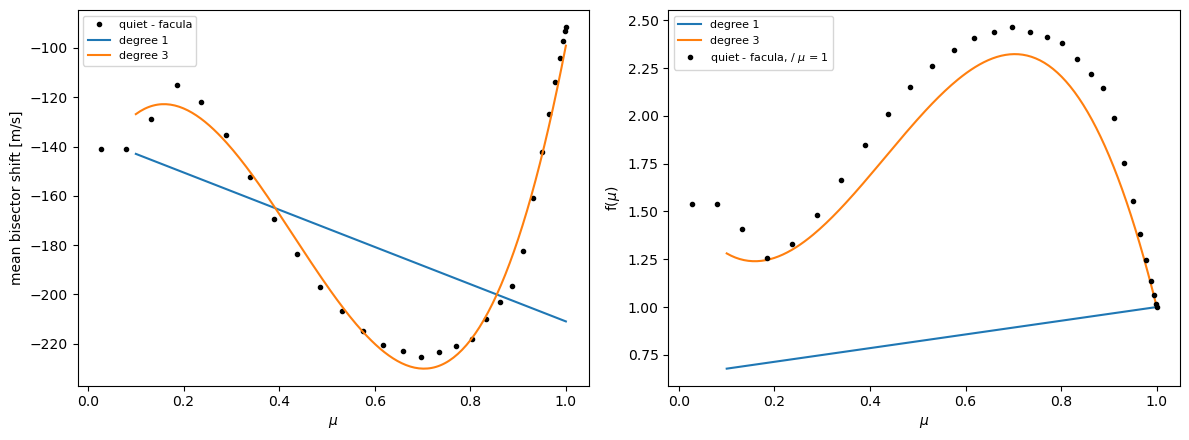

In [11]:
facula_shift = relative_to_quiet(bisectors['facula'])[:, 0].mean(1)      # quiet - facula, mean over the heights [m/s]
mu_fit = np.linspace(ccf_fac.limb_lim, 1, 200)                            # uniform in mu, without the extrapolated limb
shift_fit = np.interp(mu_fit, amu_ring[::-1], facula_shift[::-1])

facula_mu_scalings = {}                # degree -> (amplitude [m/s], f(mu) with f(1) = 1)
for deg in (1, 3):
    M = np.vstack([(mu_fit - 1)**k for k in range(deg + 1)]).T
    coef = np.linalg.lstsq(M, shift_fit, rcond=None)[0]
    f = np.polynomial.Polynomial(coef / coef[0])(np.polynomial.Polynomial([-1, 1]))
    facula_mu_scalings[deg] = (coef[0], f)
    print('degree %d: f(mu) = %s (increasing powers), rms %.1f m/s' % (deg, np.round(f.coef, 3), np.std(shift_fit - coef[0] * f(mu_fit))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(amu_ring, facula_shift, 'k.', label='quiet - facula')
for deg, (c, f) in facula_mu_scalings.items():
    axes[0].plot(mu_fit, c * f(mu_fit), label='degree %d' % deg)
    axes[1].plot(mu_fit, f(mu_fit), label='degree %d' % deg)
axes[1].plot(amu_ring, facula_shift / facula_shift[0], 'k.', label='quiet - facula, / $\\mu$ = 1')
axes[0].set_ylabel('mean bisector shift [m/s]')
axes[1].set_ylabel('f($\\mu$)')
for ax in axes:
    ax.set_xlabel('$\\mu$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Facula transit (same filling factor)

In [12]:
facula = [active_region('fc', 10, 90, 180)]     # same size and position as the spot

ss = StarSim(time, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
             differential_rotation=differential_rotation, active_regions_map=facula, mode=['photometry'],
             stellar_radius=stellar_radius,
             flux_grid_qp=phot_quiet.grid, flux_grid_sp=phot_quiet.grid, flux_grid_fc=phot_fc.grid)
ss.generate_timeseries(verbose=False)
photometry_fc = 100 * (ss.flux_var / phot_quiet.total_brightness - 1)

ss = StarSim(time, N_rings_ccf, inclination=inclination, rotation_period=rotation_period,
             differential_rotation=differential_rotation, active_regions_map=facula, mode=['ccf'],
             stellar_radius=stellar_radius, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_quiet, ccf_grid_fc=ccf_fac)
ss.generate_timeseries(verbose=False)
assert ss.ff_fc[0] == 0
assert np.allclose(ss.ff_fc, ccf[spot_dTs[0], 'Dumusque (1, 0)']['ff_sp'])
ccf_fc = {'ff_fc': ss.ff_fc.copy(),
          'rv': ss.rv_var - ss.rv_var[0],
          'fwhm': ss.fwhm_var - ss.fwhm_var[0],
          'bis': ss.bis_var - ss.bis_var[0]}


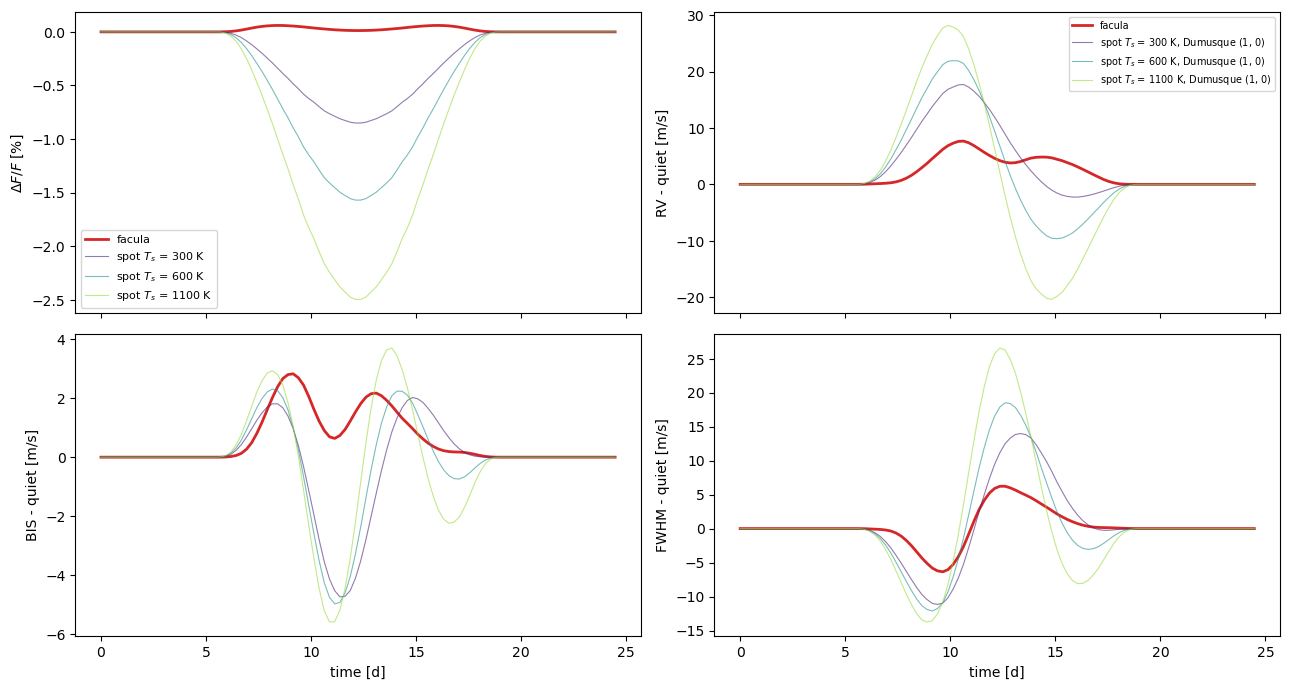

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
ax = axes[0, 0]
ax.plot(time, photometry_fc, 'C3', lw=2, label='facula')
for dT in spot_dTs:
    ax.plot(time, photometry[dT], color=colors[dT], lw=0.8, alpha=0.6, label='spot $T_s$ = %d K' % dT)
ax.set_ylabel('$\\Delta F / F$ [%]')
ax.legend(fontsize=8)

for ax, key, label in ((axes[0, 1], 'rv', 'RV'), (axes[1, 0], 'bis', 'BIS'), (axes[1, 1], 'fwhm', 'FWHM')):
    ax.plot(time, ccf_fc[key], 'C3', lw=2, label='facula')
    for dT in spot_dTs:
        ax.plot(time, ccf[dT, 'Dumusque (1, 0)'][key], color=colors[dT], lw=0.8, alpha=0.6,
                label='spot $T_s$ = %d K, Dumusque (1, 0)' % dT)
    ax.set_ylabel('%s - quiet [m/s]' % label)
axes[0, 1].legend(fontsize=7)
for ax in axes[1]:
    ax.set_xlabel('time [d]')
plt.tight_layout()
plt.show()


In [14]:
print('%-8s %10s %10s %10s %10s' % ('', 'dF/F [%]', 'RV [m/s]', 'BIS [m/s]', 'FWHM [m/s]'))
print('%-8s %10.4f %10.3f %10.3f %10.3f' % ('facula', np.ptp(photometry_fc), np.ptp(ccf_fc['rv']),
                                          np.ptp(ccf_fc['bis']), np.ptp(ccf_fc['fwhm'])))


           dF/F [%]   RV [m/s]  BIS [m/s] FWHM [m/s]
facula       0.0601      7.672      2.831     12.592


## Dumusque $\mu$ scaling from Palumbo et al. (2024)

The spots of Palumbo, Saar & Haywood (2024, ApJ 973, 11, Appendix B; SDO/HMI 2014-2018, every 4 h): $\Delta v_{conv} = v - v_{quiet}(\mu)$ of the umbrae ($I < 0.45\,\langle I_{quiet}\rangle$) and of the penumbrae ($0.45 - 0.89$). The target is the spot as a whole, its light weighted: $0.1$ umbra $+ 0.9$ penumbra.

The Dumusque bisector times $f$ shifts the fitted RV of a ring by $f\,D(\mu)$, with $D$ the shift of the bisector $\times 1$. In every ring, the factor that gives the target is

$$f(\mu) = \frac{\Delta v_{target}(\mu) - [RV_{spot} - RV_{quiet}](\mu)}{D(\mu)},$$

fitted for $0.15 \le \mu \le 0.95$ (the bins of Palumbo et al.) with a cubic $g(\mu) = c_0 + c_1\mu + c_2\mu^2 + c_3\mu^3$: `dumusque_bisector(mu_scaling=(c0, c1, c2, c3))`. Below $\mu = 0.15$, $g$ is extrapolated. Same computation in `spot_dumusque_palumbo.py`.

In [15]:
from spot_dumusque_palumbo import PALUMBO, PALUMBO_MU

w_umbra = 0.1                          # fraction of the light of a spot in its umbra
target_bins = w_umbra * PALUMBO['umbra'] + (1 - w_umbra) * PALUMBO['penumbra']
target = np.interp(amu_ring, PALUMBO_MU, target_bins)
in_palumbo = (amu_ring >= PALUMBO_MU[0]) & (amu_ring <= PALUMBO_MU[-1])

palumbo = {}                           # dT -> base, D, f, mu_scaling (c0, c1, c2, c3), grid and dv (spot - quiet) with it
for dT in spot_dTs:
    g = make_ccf_grid(cooler(flux_sp_raw, dT), ring_brightness(cooler(flux_sp_low_raw, dT), 'sp')[1], 1)
    g.rv_treatment(bisector=None)
    base = ring_rv_fit(g) - ring_rvs['quiet']                    # spot - quiet without bisector
    g.rv_treatment(bisector=dumusque_bisector(normalization=False))
    D = ring_rv_fit(g) - ring_rvs['quiet'] - base                # shift of the Dumusque bisector x 1
    f = (target - base) / D
    c = tuple(np.polyfit(amu_ring[in_palumbo], f[in_palumbo], 3)[::-1])
    g.rv_treatment(bisector=dumusque_bisector(normalization=False, mu_scaling=c))
    dv = ring_rv_fit(g) - ring_rvs['quiet']
    palumbo[dT] = dict(base=base, D=D, f=f, mu_scaling=c, grid=g, dv=dv)
    print('T_s = %d K: mu_scaling = (%s), rms vs target %.1f m/s'
          % (dT, ', '.join('%.4f' % x for x in c), np.std((dv - target)[in_palumbo])))

T_s = 300 K: mu_scaling = (-1.6960, 4.3297, -2.1253, 0.2519), rms vs target 2.2 m/s


T_s = 600 K: mu_scaling = (-1.6823, 4.3085, -2.1036, 0.2444), rms vs target 2.2 m/s


T_s = 1100 K: mu_scaling = (-1.6562, 4.2700, -2.0638, 0.2306), rms vs target 2.2 m/s


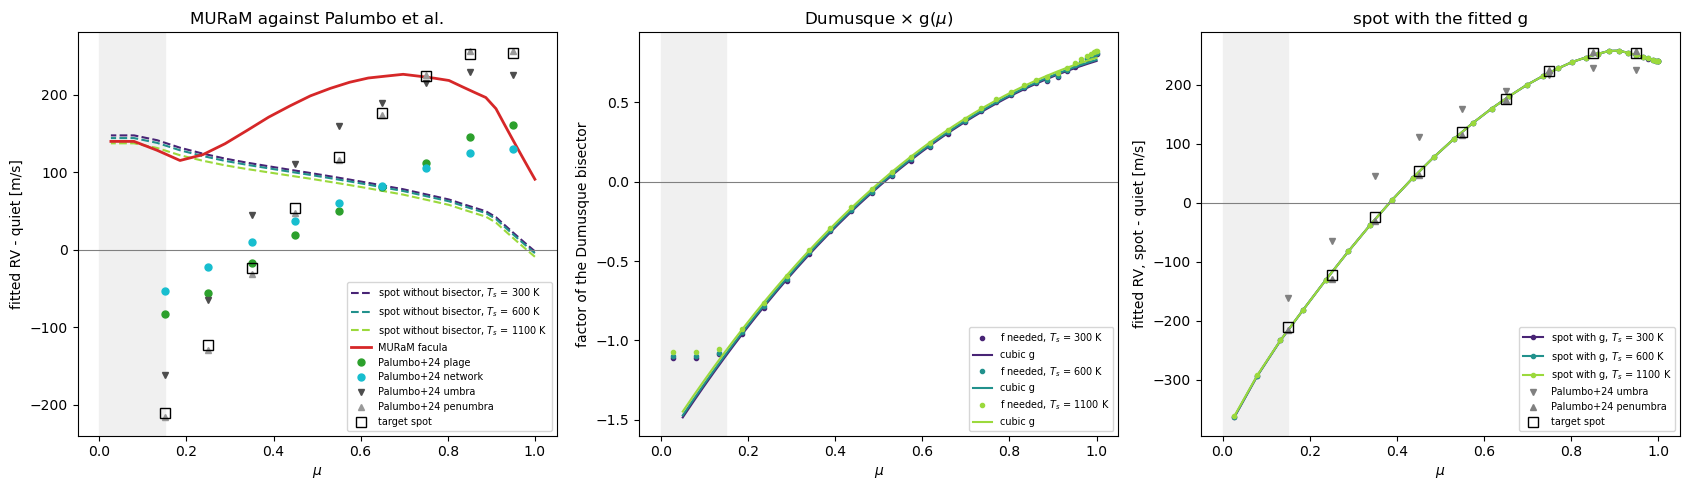

In [16]:
mu_fine = np.linspace(0.05, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
for dT in spot_dTs:
    ax.plot(amu_ring, palumbo[dT]['base'], '--', color=colors[dT], label='spot without bisector, $T_s$ = %d K' % dT)
ax.plot(amu_ring, ring_rvs['facula'] - ring_rvs['quiet'], 'C3', lw=2, label='MURaM facula')
for q, (c, m) in {'plage': ('C2', 'o'), 'network': ('C9', 'o'), 'umbra': ('0.3', 'v'), 'penumbra': ('0.6', '^')}.items():
    ax.plot(PALUMBO_MU, PALUMBO[q], m, color=c, ms=5, label='Palumbo+24 %s' % q)
ax.plot(PALUMBO_MU, target_bins, 'ks', mfc='none', ms=7, label='target spot')
ax.set_ylabel('fitted RV - quiet [m/s]')
ax.set_title('MURaM against Palumbo et al.')

ax = axes[1]
for dT in spot_dTs:
    ax.plot(amu_ring, palumbo[dT]['f'], '.', color=colors[dT], label='f needed, $T_s$ = %d K' % dT)
    ax.plot(mu_fine, np.polynomial.Polynomial(palumbo[dT]['mu_scaling'])(mu_fine), color=colors[dT], label='cubic g')
ax.set_ylabel('factor of the Dumusque bisector')
ax.set_title('Dumusque $\\times$ g($\\mu$)')

ax = axes[2]
for dT in spot_dTs:
    ax.plot(amu_ring, palumbo[dT]['dv'], '.-', color=colors[dT], label='spot with g, $T_s$ = %d K' % dT)
for q, m in (('umbra', 'v'), ('penumbra', '^')):
    ax.plot(PALUMBO_MU, PALUMBO[q], m, color='0.5', ms=5, label='Palumbo+24 %s' % q)
ax.plot(PALUMBO_MU, target_bins, 'ks', mfc='none', ms=7, label='target spot')
ax.set_ylabel('fitted RV, spot - quiet [m/s]')
ax.set_title('spot with the fitted g')
for ax in axes:
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvspan(0, PALUMBO_MU[0], color='0.94', zorder=0)
    ax.set_xlabel('$\\mu$')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### The component pipeline (`PIC/bisectors_components.txt`, row `palumbo`)

The pipeline builds the spot differently: the 200 G SSD spectrum $\times$ the black body ratio (`mps_highres`, `ccf_norm = 0`, 60 rings) and `remove_bis_spot = 1`, the bisector of the spot CCF removed before the Dumusque bisector is added. Without its bisector the spot CCF is at 0 m/s, while the MURaM quiet CCF is at $-600$ to $-1000$ m/s with this mask: the spot starts $\sim +950$ m/s from the quiet Sun, and the factor that brings it to Palumbo et al. is $\sim -2.5$. Results of `python spot_dumusque_palumbo.py --pipeline` (the configurations built with `write_conf` of `PIC/settings.sh` and read by `simulate_old_config`).

T_s = 300 K: dumusque_mu_scaling = -2.1506,-3.4333,6.4040,-3.0952, rms vs target 2.3 m/s (configuration built again: 2.3 m/s)
T_s = 600 K: dumusque_mu_scaling = -2.1508,-3.4295,6.4014,-3.0946, rms vs target 2.3 m/s (configuration built again: 2.3 m/s)
T_s = 1100 K: dumusque_mu_scaling = -2.1511,-3.4176,6.3844,-3.0857, rms vs target 2.3 m/s (configuration built again: 2.3 m/s)


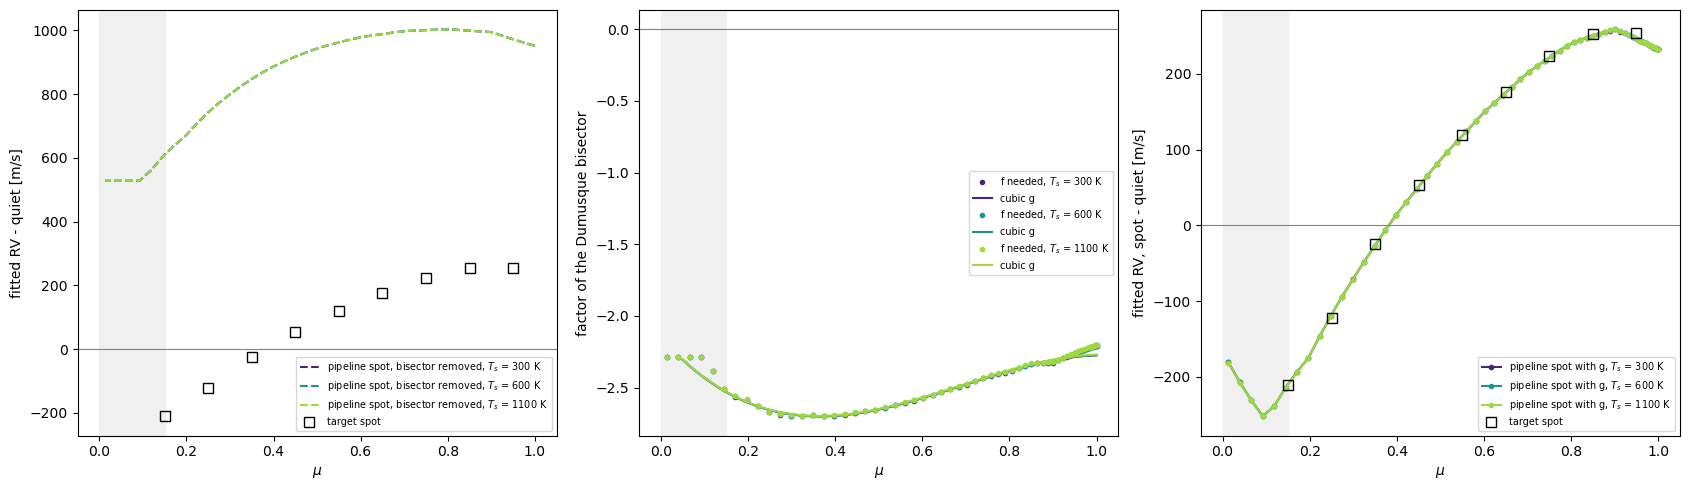

palumbo  1  1.0  -2.1506,-3.4333,6.4040,-3.0952


In [17]:
import json
with open('results/spot_dumusque_palumbo/spot_dumusque_palumbo_pipeline.json') as fh:
    pipe = json.load(fh)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for dT in spot_dTs:
    r = pipe['dT'][str(dT)]
    mu, base, D, f = (np.array(r[k]) for k in ('mu_rings', 'base', 'D', 'f'))
    c = [float(x) for x in r['dumusque_mu_scaling']['3'].split(',')]
    g = np.polynomial.Polynomial(c)
    axes[0].plot(mu, base, '--', color=colors[dT], label='pipeline spot, bisector removed, $T_s$ = %d K' % dT)
    axes[1].plot(mu, f, '.', color=colors[dT], label='f needed, $T_s$ = %d K' % dT)
    axes[1].plot(mu_fine, g(mu_fine), color=colors[dT], label='cubic g')
    axes[2].plot(mu, base + g(mu) * D, '.-', color=colors[dT], label='pipeline spot with g, $T_s$ = %d K' % dT)
    print('T_s = %d K: dumusque_mu_scaling = %s, rms vs target %.1f m/s (configuration built again: %.1f m/s)'
          % (dT, r['dumusque_mu_scaling']['3'], r['rms']['3'], r['rms_check']['3']))
for ax in (axes[0], axes[2]):
    ax.plot(PALUMBO_MU, target_bins, 'ks', mfc='none', ms=7, label='target spot')
axes[0].set_ylabel('fitted RV - quiet [m/s]')
axes[1].set_ylabel('factor of the Dumusque bisector')
axes[2].set_ylabel('fitted RV, spot - quiet [m/s]')
for ax in axes:
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvspan(0, PALUMBO_MU[0], color='0.94', zorder=0)
    ax.set_xlabel('$\\mu$')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
print([l.rstrip() for l in open('../PIC/bisectors_components.txt') if l.startswith('palumbo')][0])

### Spot transit with the Palumbo scaling

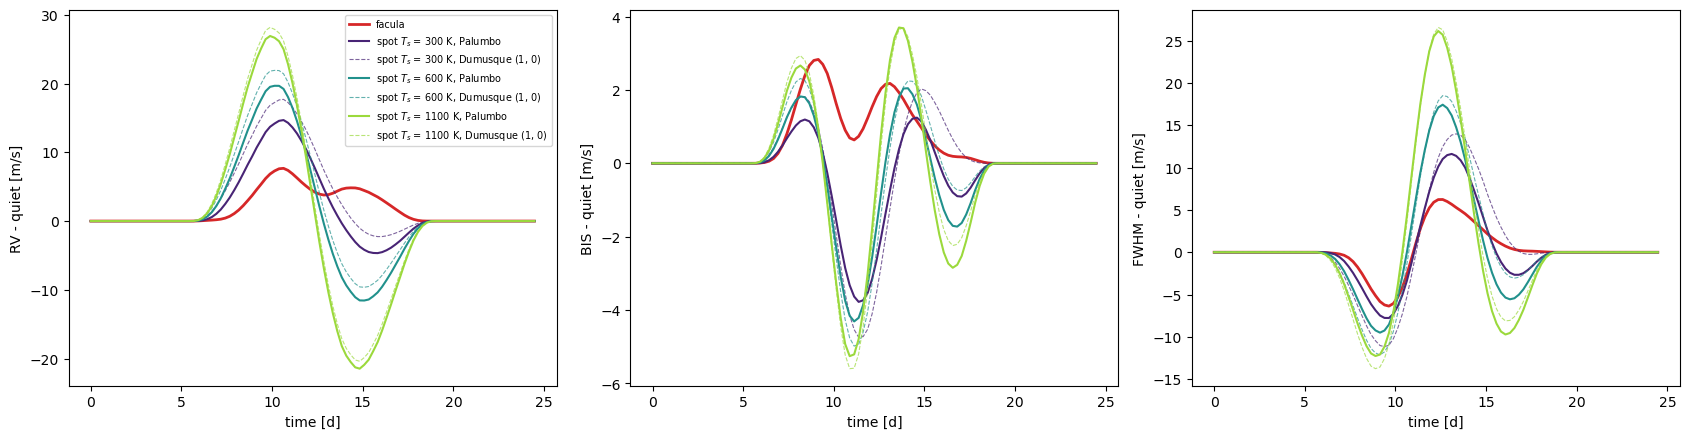

                               RV [m/s]  BIS [m/s] FWHM [m/s]
spot 300 K, Palumbo              19.353      5.021     19.377
spot 300 K, Dumusque (1, 0)      19.964      6.767     25.133
spot 600 K, Palumbo              31.237      6.356     26.919
spot 600 K, Dumusque (1, 0)      31.552      7.294     30.630
spot 1100 K, Palumbo             48.393      8.956     38.382
spot 1100 K, Dumusque (1, 0)     48.570      9.301     40.302


In [18]:
for dT in spot_dTs:
    ss = StarSim(time, N_rings_ccf, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=differential_rotation, active_regions_map=spot, mode=['ccf'],
                 stellar_radius=stellar_radius, ccf_grid_qp=ccf_quiet, ccf_grid_sp=palumbo[dT]['grid'], ccf_grid_fc=ccf_fac)
    ss.generate_timeseries(verbose=False)
    ccf[dT, 'Palumbo'] = {'ff_sp': ss.ff_sp.copy(),
                          'rv': ss.rv_var - ss.rv_var[0],
                          'fwhm': ss.fwhm_var - ss.fwhm_var[0],
                          'bis': ss.bis_var - ss.bis_var[0]}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)
for ax, key, label in zip(axes, ('rv', 'bis', 'fwhm'), ('RV', 'BIS', 'FWHM')):
    ax.plot(time, ccf_fc[key], 'C3', lw=2, label='facula')
    for dT in spot_dTs:
        ax.plot(time, ccf[dT, 'Palumbo'][key], color=colors[dT], lw=1.5, label='spot $T_s$ = %d K, Palumbo' % dT)
        ax.plot(time, ccf[dT, 'Dumusque (1, 0)'][key], '--', color=colors[dT], lw=0.8, alpha=0.7,
                label='spot $T_s$ = %d K, Dumusque (1, 0)' % dT)
    ax.set_ylabel('%s - quiet [m/s]' % label)
    ax.set_xlabel('time [d]')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

print('%-28s %10s %10s %10s' % ('', 'RV [m/s]', 'BIS [m/s]', 'FWHM [m/s]'))
for dT in spot_dTs:
    for name in ('Palumbo', 'Dumusque (1, 0)'):
        print('%-28s %10.3f %10.3f %10.3f' % ('spot %d K, %s' % (dT, name), *(np.ptp(ccf[dT, name][k]) for k in ('rv', 'bis', 'fwhm'))))